In [74]:
import baltic as bt
import pandas as pd
import json
import os
import sys
import subprocess
import glob
import shutil
import re
import importlib
import numpy as np
import matplotlib as mpl
from plotnine import *
from plotnine import geom_line
from datetime import datetime
import geopandas as gpd
import geodatasets
from shapely.geometry import Polygon, MultiPolygon

In [75]:
%matplotlib inline
from matplotlib import pyplot as plt
import matplotlib.patheffects as path_effects
import matplotlib.lines as mlines
from matplotlib.font_manager import FontProperties
import matplotlib.colors as clr
import textwrap as textwrap
from textwrap import wrap

In [76]:
# I think this is basic font information
mpl.rc('font',**{'family':'sans-serif','sans-serif':['Helvetica']})
mpl.rc('text', usetex='false') 
mpl.rcParams.update({'font.size': 22})

In [4]:
# Read in the path to the tree

# 60 per division per year 
#tree_path_1 = f"./Nextstrain/12052024_NAm_aves-wild_divisionyear/Nextstrain_builds/h5nx_ha.json"

# 5 per division per month per year
#tree_path_2 = f"./Nextstrain/12052024_NAm_aves-wild_divisionmonth/Nextstrain_builds/h5nx_ha.json"

# County priority Nextstrain tree
tree_path = f"./Nextstrain/2025-02-24_NAm_aves-wild_division_nopacific_countypriority/Nextstrain_builds/h5nx_ha.json"

# 2022 only Nextstrain tree
tree_path = f"./Nextstrain/2025-01-07_NAm_aves-wild_division2022/Nextstrain_builds/h5nx_ha.json"

In [5]:
#mytree1, mymeta1 = bt.loadJSON(tree_path_1)

In [6]:
#mytree2, mymeta2 = bt.loadJSON(tree_path_2)

In [7]:
mytree, mymeta = bt.loadJSON(tree_path)


Tree height: 0.992881
Tree length: 110.025831
annotations present

Numbers of objects in tree: 1153 (451 nodes and 702 leaves)



In [8]:
# Function: Make a dataframe that counts the instances of traits across tips

def traits_across_tips(trait, tree):

    trait_list = []
    
    for k in tree.Objects:
        if k.branchType == "leaf":
            trait_list.append(k.traits[trait])

    trait_df = pd.DataFrame(data = trait_list)

    trait_counts = pd.DataFrame(data = trait_df.value_counts())
    trait_counts.reset_index(inplace = True)
    trait_counts.rename(columns={0:trait, 1: 'count'}, inplace = True)

    return(trait_counts)

In [56]:
division_year_counts = traits_across_tips("division", mytree1)

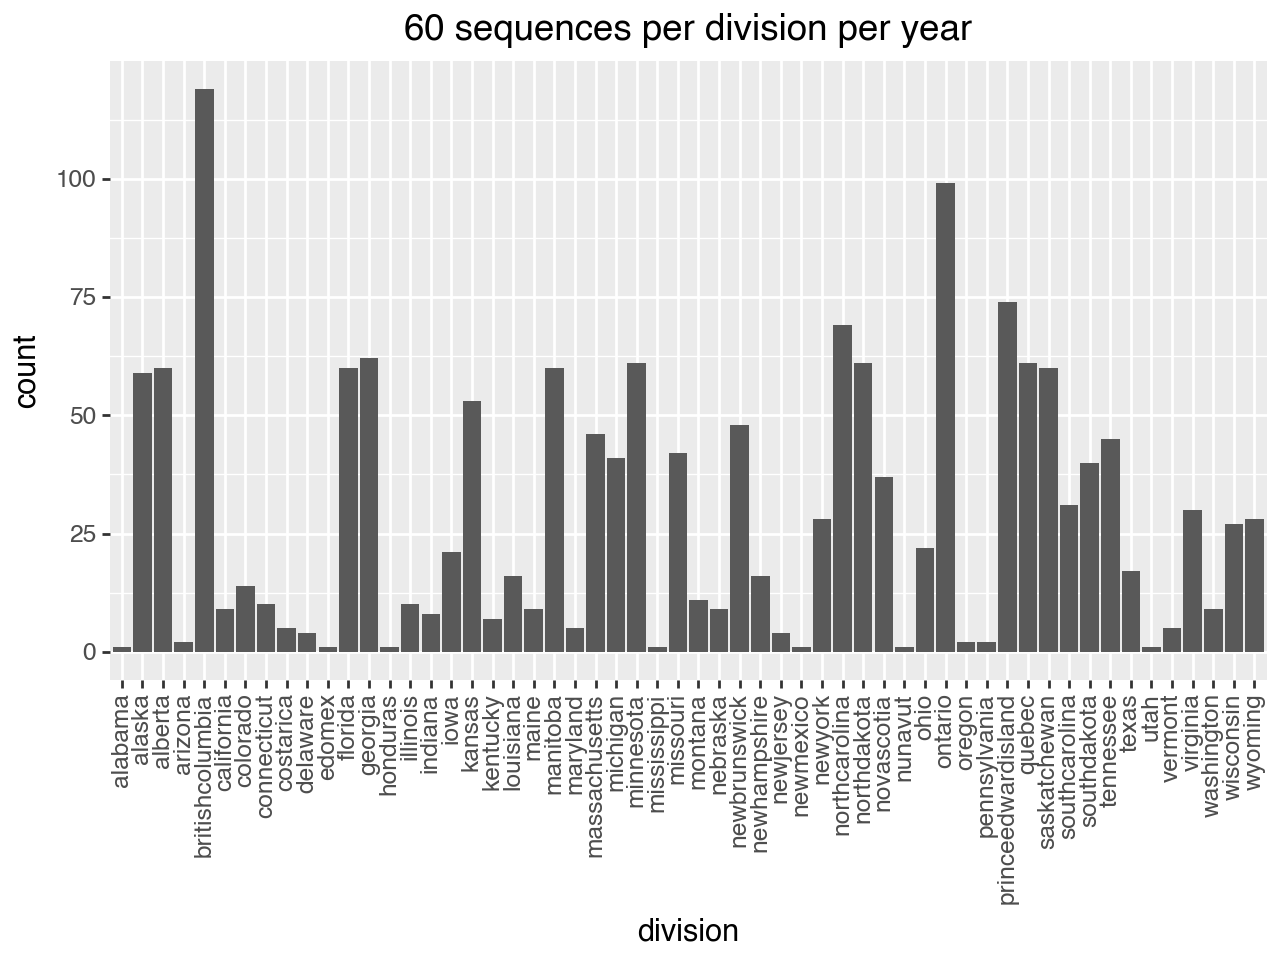

In [59]:
# Make a plot

(
    ggplot(division_year_counts, aes(x = "division", y = "count")) 
    + geom_bar(stat = "identity")
    + labs(title = "60 sequences per division per year")
    + theme(axis_text_x = element_text(rotation = 90))
)

In [51]:
division_month_counts = traits_across_tips("division", mytree2)

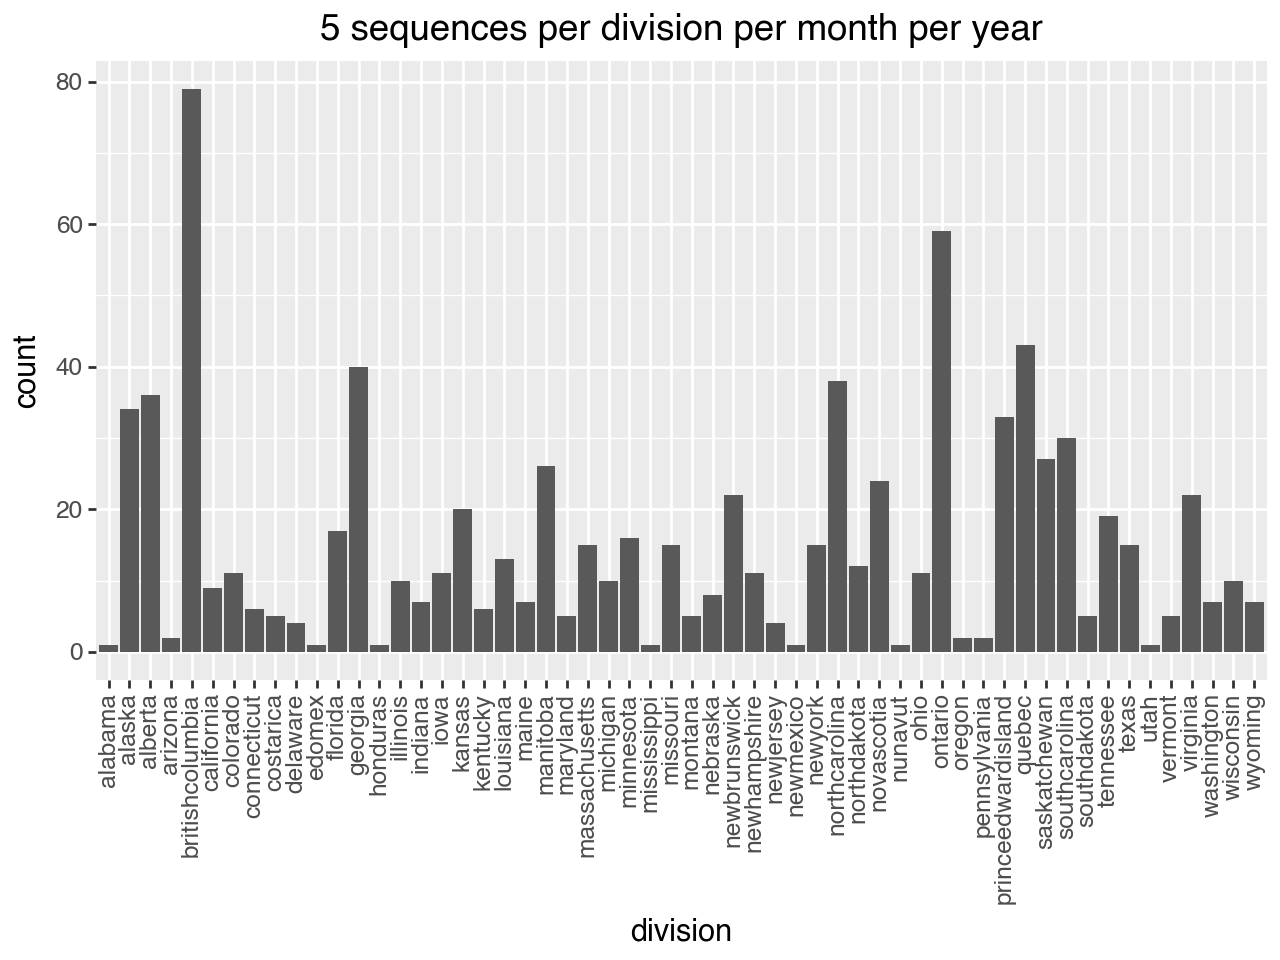

In [54]:
# Make a plot

(
    ggplot(division_month_counts, aes(x = "division", y = "count")) 
    + geom_bar(stat = "identity")
    + labs(title = "5 sequences per division per month per year")
    + theme(axis_text_x = element_text(rotation = 90))
)

In [42]:
# I am not sure what this code does...
print(mytree)
count = 0

for k in mytree.Objects: 
    #print(k.branchType)
    count += 1
    
    if k.branchType == "leaf" and count <= 1: 
        print(k.traits["name"])
    elif k.branchType == "node" and count <= 1:
        print(k.traits)
        #print(k.leaves)
        #print(k.children)
        #print(k.parent)

{'name': 'NODE_0000000', 'node_attrs': {'div': 0, 'num_date': {'value': 2021.932092981308, 'confidence': [2021.6371293246648, 2021.9799209034863]}, 'domesticstatus_combined': {'value': 'wild', 'confidence': {'wild': 0.999999495377418}, 'entropy': 7.821372900218281e-06}, 'date': {'value': '2021-12-07'}, 'division': {'value': 'princeedwardisland', 'confidence': {'newbrunswick': 0.011360556907878568, 'northcarolina': 0.4509722878610676, 'novascotia': 0.01173483120959238, 'princeedwardisland': 0.4557180145293599}, 'entropy': 1.2747010257339897}, 'bird_order': {'value': 'suliformes', 'confidence': {'accipitriformes': 0.019142704869478465, 'anseriformes': 0.4173932254118134, 'charadriiformes': 0.024540670160625038, 'suliformes': 0.5067023696216428}, 'entropy': 1.0387383675261241}, 'NAflyway': {'value': 'AtlanticFlyway', 'confidence': {'AtlanticFlyway': 0.9966839725260594, 'MississippiFlyway': 0.003158074422972409}, 'entropy': 0.0229430406217483}}, 'branch_attrs': {'mutations': {}}, 'divergen

In [16]:
# Function: extract two traits as a dataframe

def traits_across_tips_2(trait1, trait2, tree):

    name_list = []
    trait1_list = []
    trait2_list = []
    
    for k in tree.Objects:
        if k.branchType == "leaf":
            name_list.append(k.traits["name"])
            trait1_list.append(k.traits[trait1])
            trait2_list.append(k.traits[trait2])

    df = pd.DataFrame({
    'Tip': name_list,
    'trait1': trait1_list,
    'trait2': trait2_list
    })

    # trait_counts = pd.DataFrame(data = trait_df.value_counts())
    # trait_counts.reset_index(inplace = True)
    # trait_counts.rename(columns={0:trait, 1: 'count'}, inplace = True)

    # return(trait_counts)
    return(df)

In [36]:
# Generate a dataframe with the collection date and lat/long source for each tip
tree_county_time = traits_across_tips_2('num_date', 'lat_long_source', mytree)
print(tree_county_time["trait2"].value_counts())

trait2
state     2471
county    2280
city        23
Name: count, dtype: int64


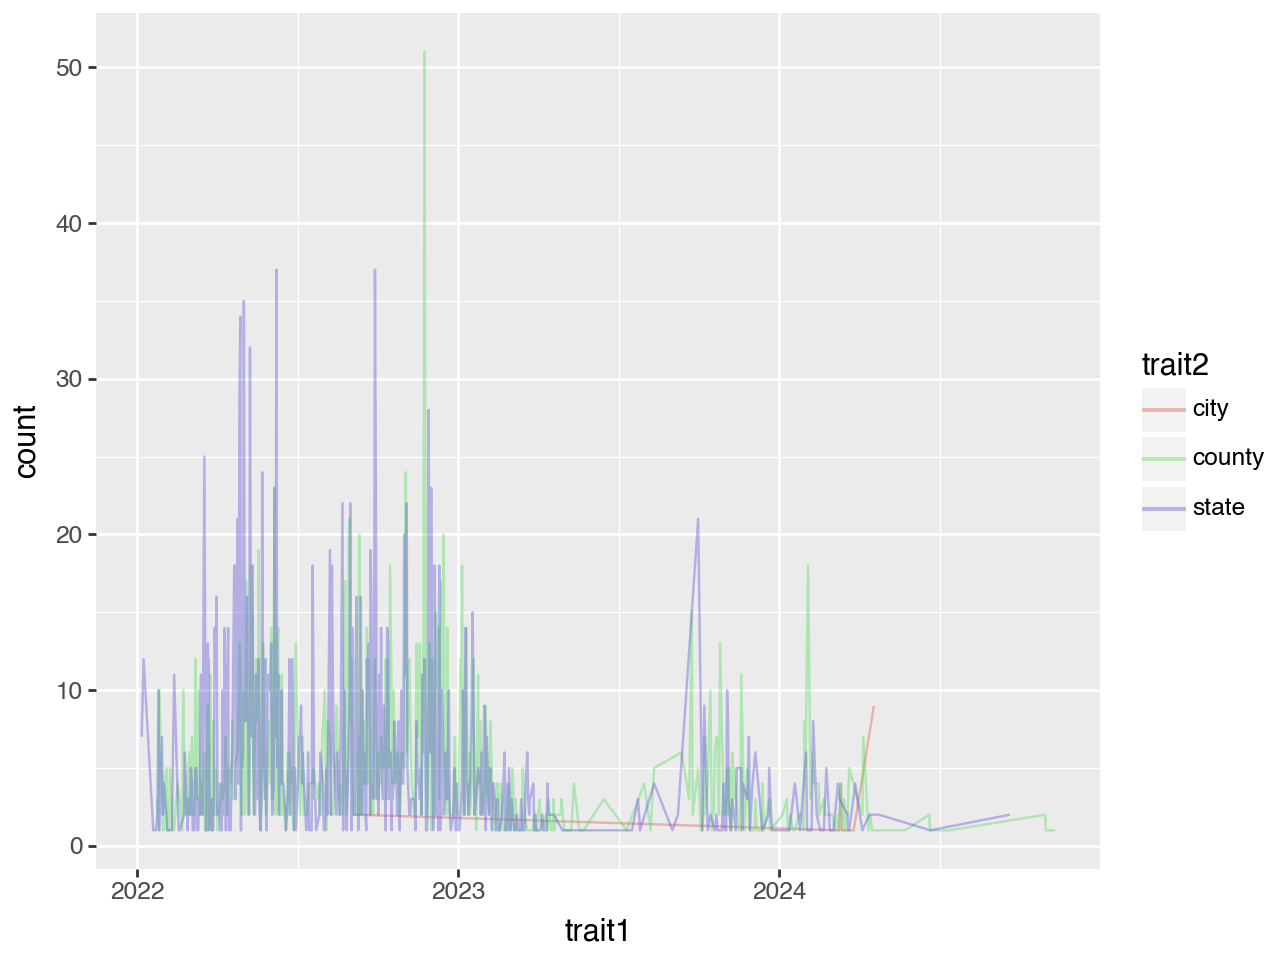

In [48]:
# Plot the number of tips with county lat/long data over time

county_over_time = (
    ggplot(tree_county_time, aes(x = "trait1", color = "trait2")) 
    + geom_line(stat = "count", alpha = 0.4)
)
county_over_time.show()

In [49]:
# The following two plots were not made using the tree (via baltic) but they go with the plot above so I am coding here

In [77]:
# Upload the TSV
FILENAME = "./Nextstrain/2025-02-24_NAm_aves-wild_division_nopacific_countypriority/Nextstrain_results/ha_sequences_filtered-by-timetree.tsv"
timetree_sequences = pd.read_csv(FILENAME, sep = '\t')

# Limit to just nonambig_date and lat_long_to_use
columns = ["nonambig_date", "lat_long_to_use", "division"]
timetree_sequences_filtered = timetree_sequences.loc[0:, columns]
#print(timetree_sequences_filtered)

# Make a month-year column
timetree_sequences_filtered["year_month"] = timetree_sequences_filtered["nonambig_date"].str.split("-", expand = True)[0] + "-" + timetree_sequences_filtered["nonambig_date"].str.split("-", expand = True)[1]

timetree_sequences_filtered.head()

# Get value counts
# timetree_sequences_filtered_valuecounts = timetree_sequences_filtered["lat_long_to_use"].value_counts()
# print(timetree_sequences_filtered_valuecounts)

,nonambig_date,lat_long_to_use,division,year_month
0,2022-02-06,"41.47,-72.1",connecticut,2022-02
1,2022-02-16,"41.35,-72.9",connecticut,2022-02
2,2022-02-16,"41.35,-72.9",connecticut,2022-02
3,2022-02-16,"41.35,-72.9",connecticut,2022-02
4,2023-11-01,"41.284478,-86.644636",indiana,2023-11


In [5]:
def latlongpermonth(df):
    total_counts = {}
    unique_latlongs = {}

    for idx, row in df.iterrows():
        yr_mon = row['year_month']
        lat_long = row["lat_long_to_use"]


        # Update total count
        total_counts[yr_mon] = total_counts.get(yr_mon, 0) + 1

        # Add each unique lat-long to a dictionary
        if yr_mon not in unique_latlongs:
            unique_latlongs[yr_mon] = set()
        unique_latlongs[yr_mon].add(lat_long)
        
    # Convert the sets of unique lat/longs to counts
    unique_counts = {k: len(v) for k, v in unique_latlongs.items()}   

    return total_counts, unique_counts

In [6]:
total_latlong, number_unique = latlongpermonth(timetree_sequences_filtered)

In [11]:
# Convert both dictionaries to DataFrames
df_total = pd.DataFrame(list(total_latlong.items()), columns=['year_month', 'total_latlong_count'])
df_unique = pd.DataFrame(list(number_unique.items()), columns=['year_month', 'unique_latlong_count'])

# Merge the two DataFrames on 'year_month'
merged_df = pd.merge(df_total, df_unique, on='year_month')

# Optional: sort by year_month
merged_df = merged_df.sort_values('year_month').reset_index(drop=True)

# Add a column for percentage of unique lat-longs by year_month
merged_df["percent_unique"] = merged_df["unique_latlong_count"] / merged_df["total_latlong_count"]

# Add a column for rounded values of percent of unique lat-longs
merged_df["percent_unique_rounded"] = round(merged_df["percent_unique"], 1)


# View the result
merged_df.head()

,year_month,total_latlong_count,unique_latlong_count,percent_unique,percent_unique_rounded
0,2022-01,63,11,0.174603,0.2
1,2022-02,91,35,0.384615,0.4
2,2022-03,264,82,0.310606,0.3
3,2022-04,401,83,0.206983,0.2
4,2022-05,487,72,0.147844,0.1


In [116]:
# I do not know what this code does, beyond that it makes it easier for me to plot and color latlong counts
long_df = pd.melt(
    merged_df,
    id_vars=["year_month"],
    value_vars=["total_latlong_count", "unique_latlong_count"],
    var_name="type",
    value_name="count"
)

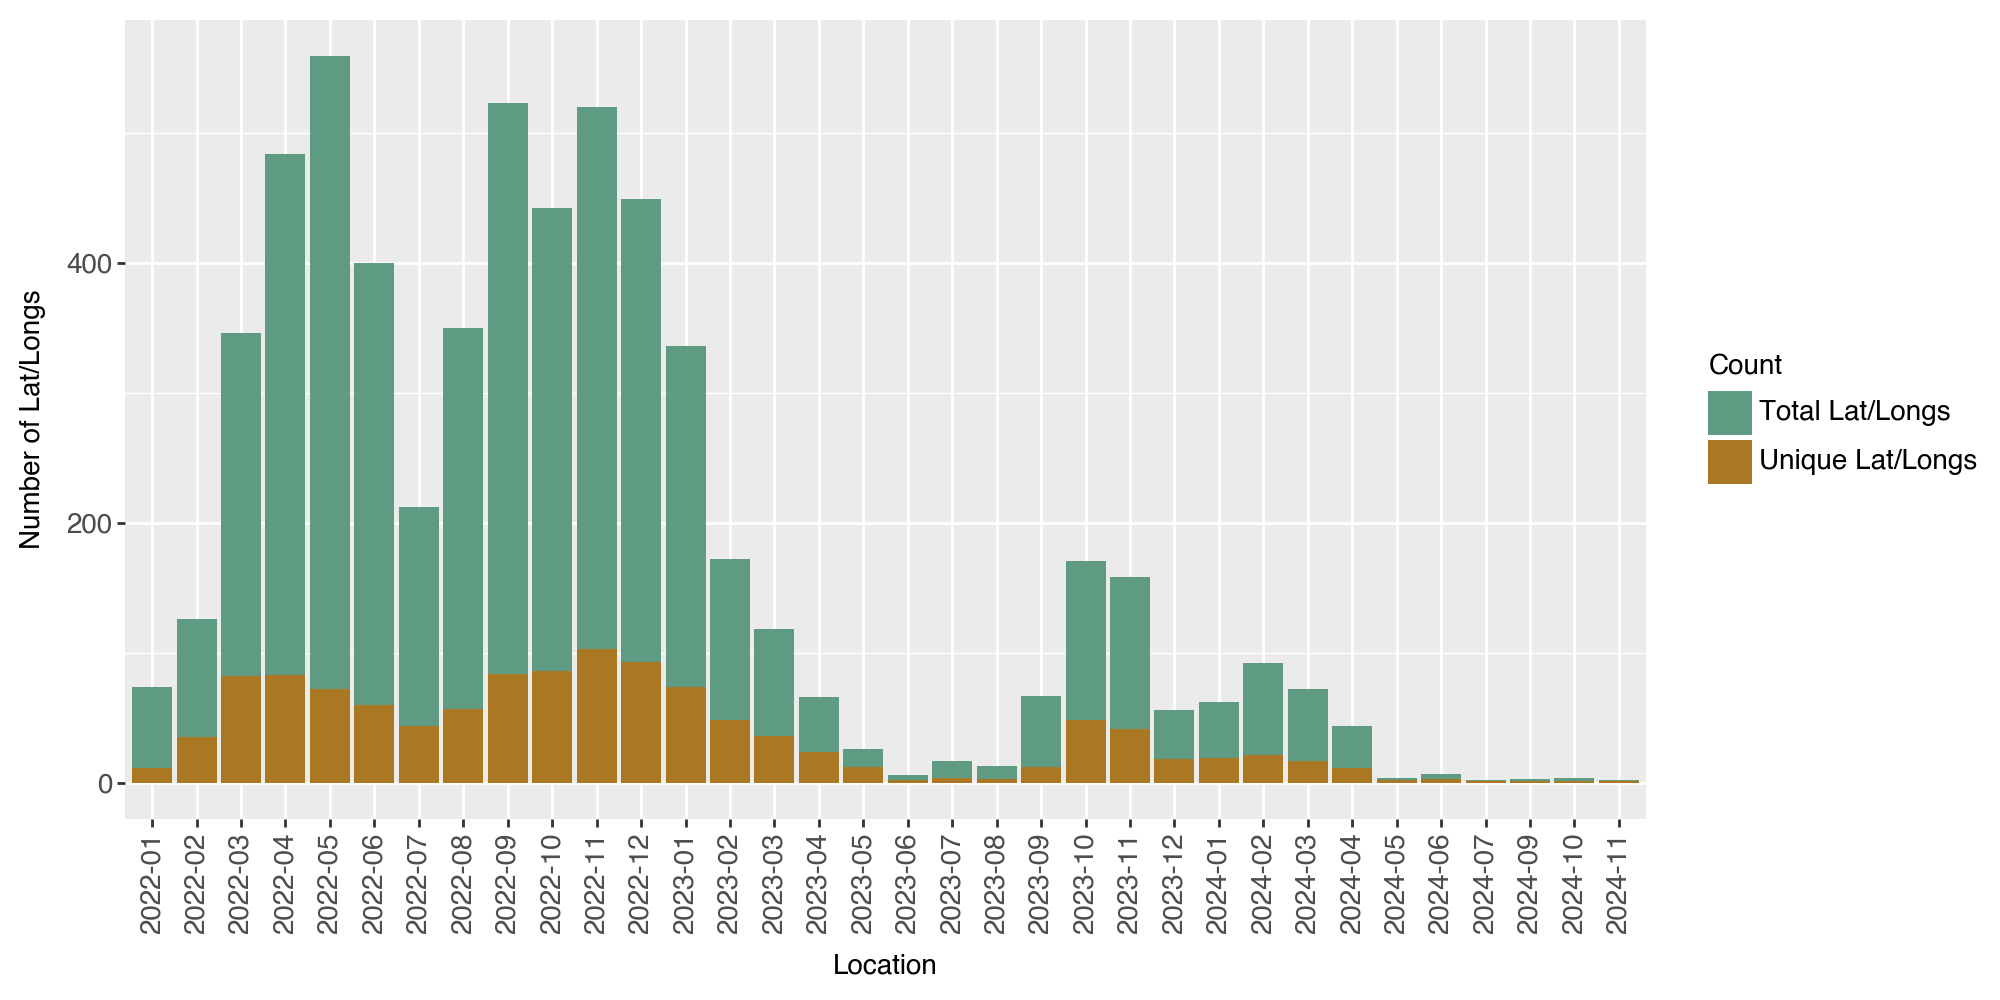

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:606: PlotnineWarning: Saving 20 x 10 in image.
/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:607: PlotnineWarning: Filename: /Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/exploratory_data_analysis/2022-2024_latlongs_by_date.png


In [122]:
# Plot total and unique lat/longs per year_month
uniquelatlong_per_month = (
    ggplot(long_df)
        + geom_col(aes(x='year_month', y='count', fill='type'), position='stack')
        + scale_fill_manual(values={"total_latlong_count": "#5E9B82", "unique_latlong_count": "#AA7722"}, name="Count", 
                            labels={"total_latlong_count":"Total Lat/Longs", "unique_latlong_count": "Unique Lat/Longs"})
        + labs(x='Location', y='Number of Lat/Longs', fill='Count Type')
        + theme(axis_text_x=element_text(rotation=90), text=element_text(size=10))
        + theme(figure_size=(10, 5))
    )

uniquelatlong_per_month.show()
uniquelatlong_per_month.save(filename = './metadata/exploratory_data_analysis/2022-2024_latlongs_by_date.png', height=10, width=20, units = 'in', dpi=750)

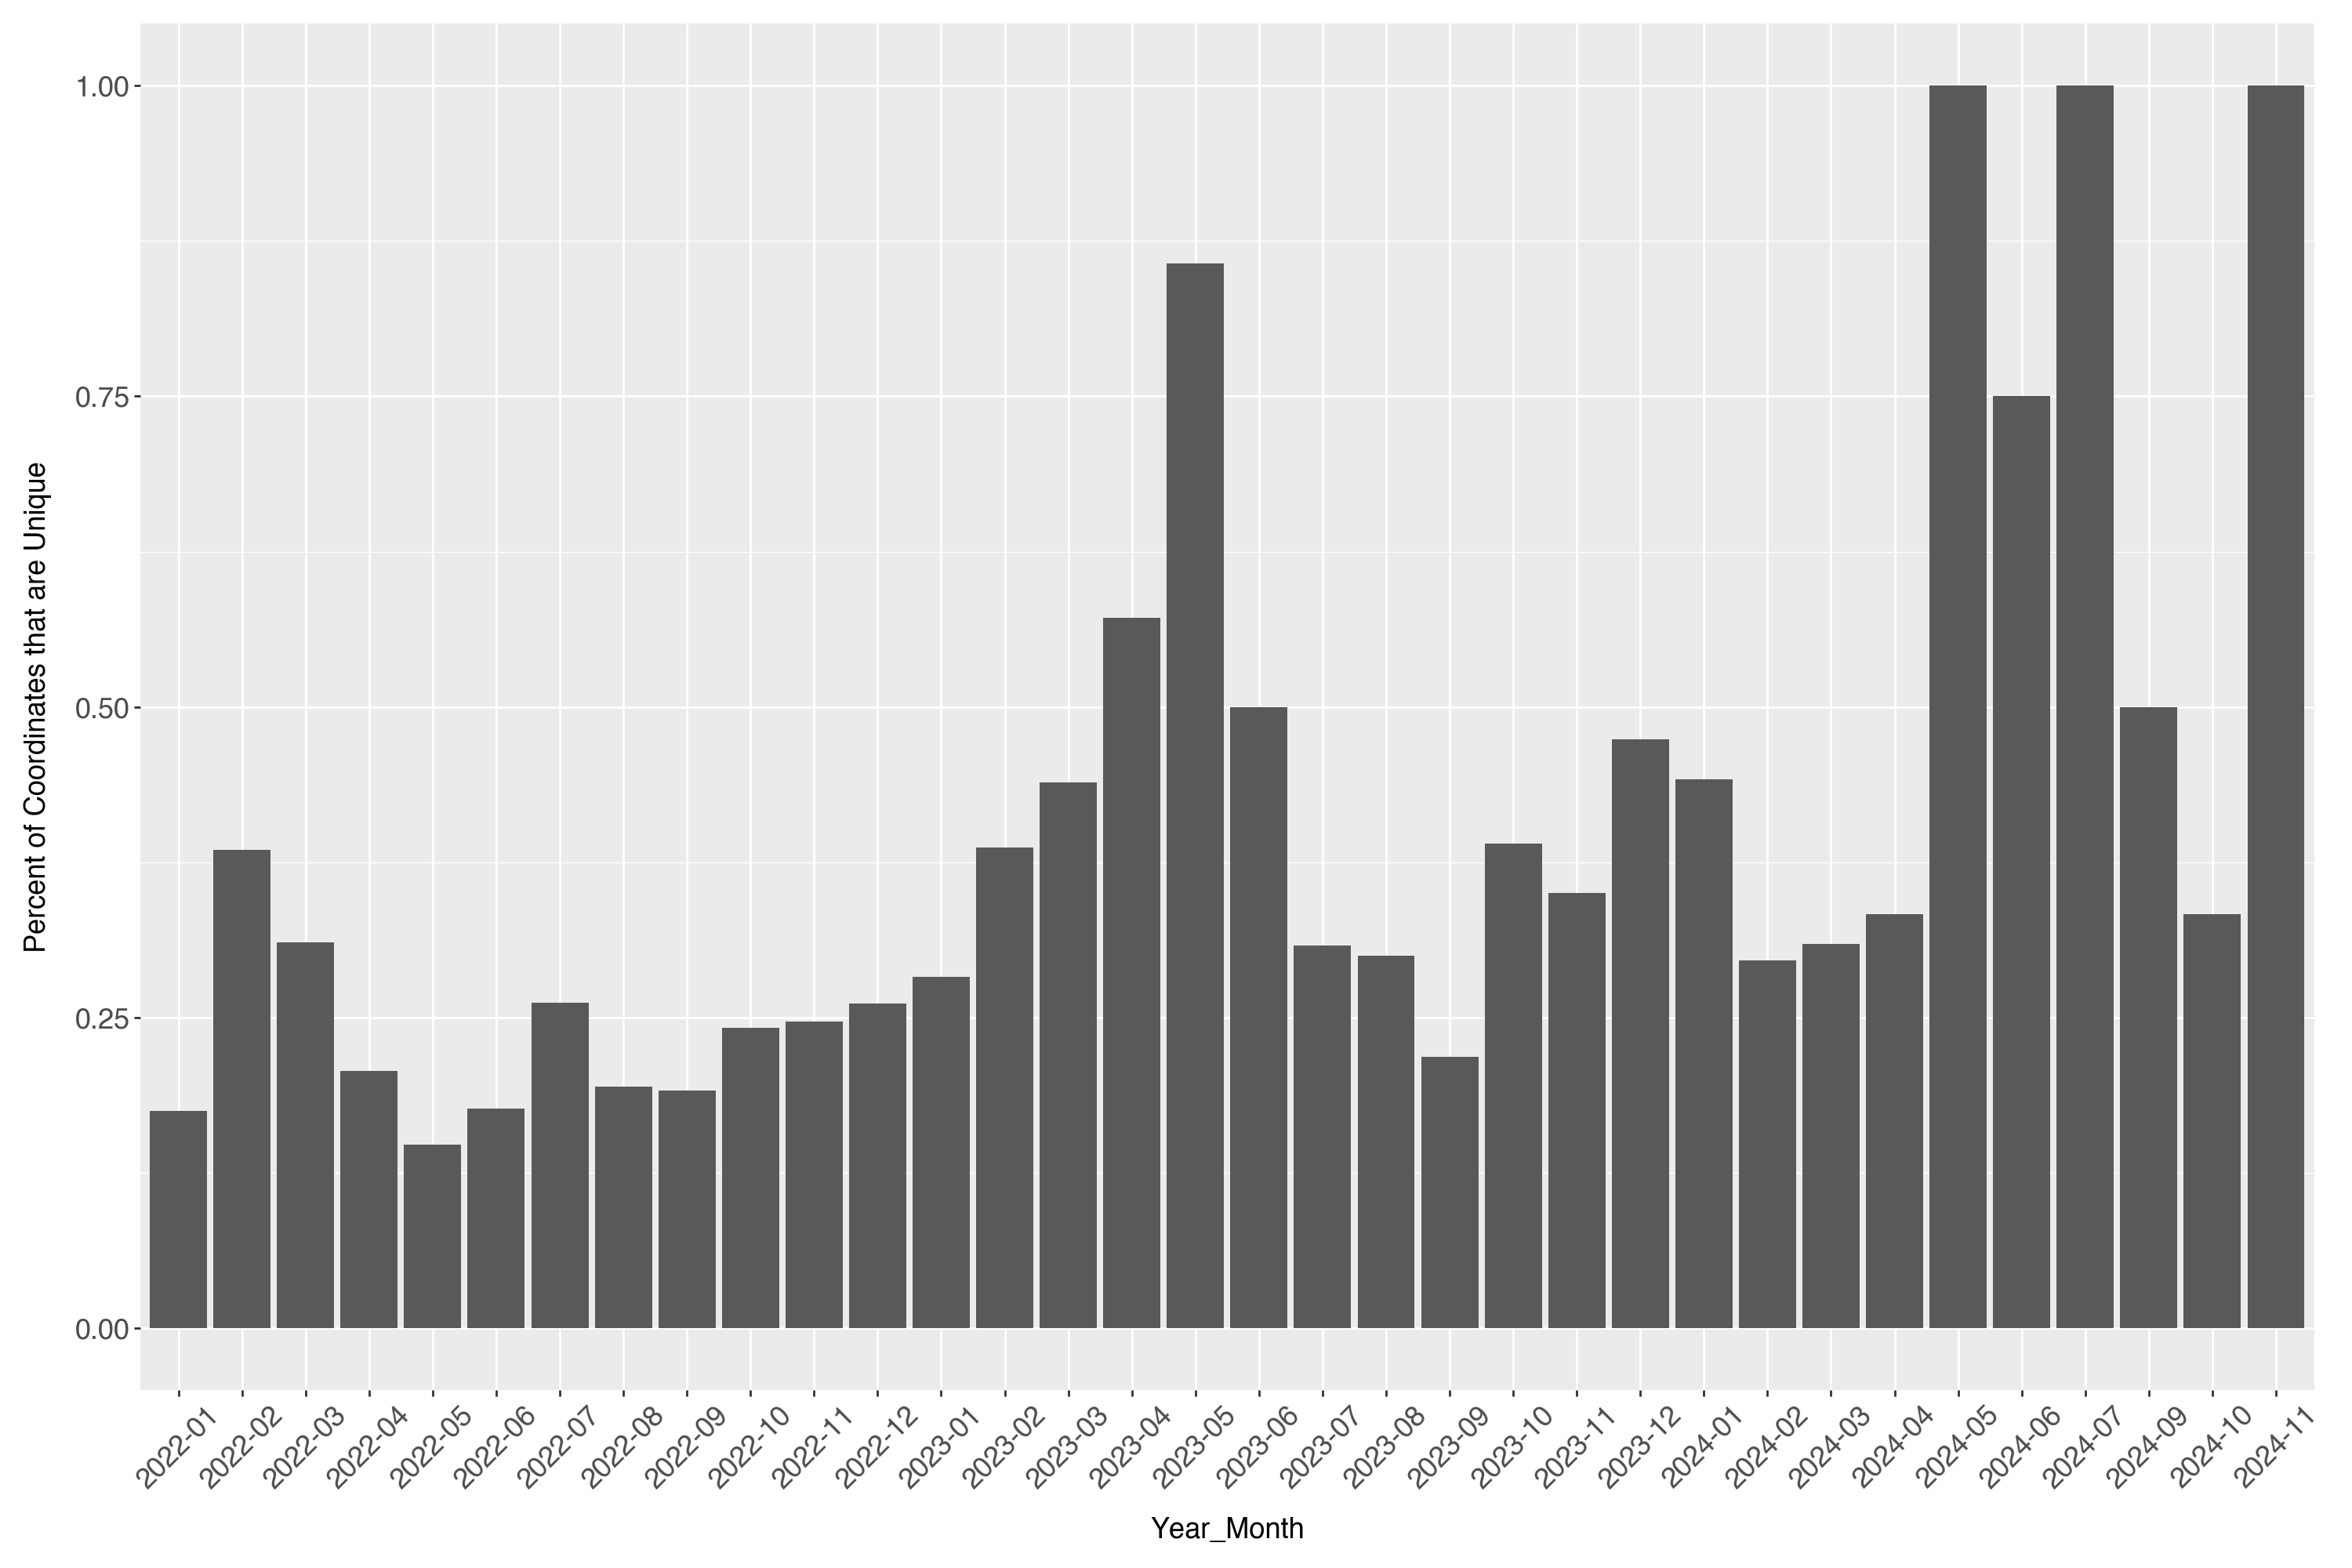

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:606: PlotnineWarning: Saving 20 x 10 in image.
/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:607: PlotnineWarning: Filename: /Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/exploratory_data_analysis/2022-2024_pct-unique-coord.png


In [9]:
proportionunique = (
    ggplot(merged_df, aes(x = "year_month", y = "percent_unique")) +
    geom_col() +
    labs(x = "Year_Month", y = "Percent of Coordinates that are Unique") +
    theme(axis_text_x = element_text(rotation = 45), text = element_text(size = 13), figure_size = (15, 10))
)

proportionunique.show()
proportionunique.save(filename = './metadata/exploratory_data_analysis/2022-2024_pct-unique-coord.png', height=10, width=20, units = 'in', dpi=750)

In [78]:
def order_uniquelatlong(df):
    unique_latlongs = {}

    for idx, row in df.iterrows():
        division = row["division"]
        lat_long = row["lat_long_to_use"]

        # Add each unique lat-long to a dictionary
        if division not in unique_latlongs:
            unique_latlongs[division] = set()
        unique_latlongs[division].add(lat_long)
        
    # Convert the sets of unique lat/longs to counts
    unique_counts = {k: len(v) for k, v in unique_latlongs.items()}   

    return unique_counts

In [114]:
# Make a dictionary of the number of unique lat/longs per division
unique_per_division = order_uniquelatlong(timetree_sequences_filtered)
#print(unique_per_division)

# Convert this to a dataframe
unique_per_division_df = pd.DataFrame(list(unique_per_division.items()), columns=['division', 'unique_latlong_count'])
unique_per_division_df["Count"] = "unique"

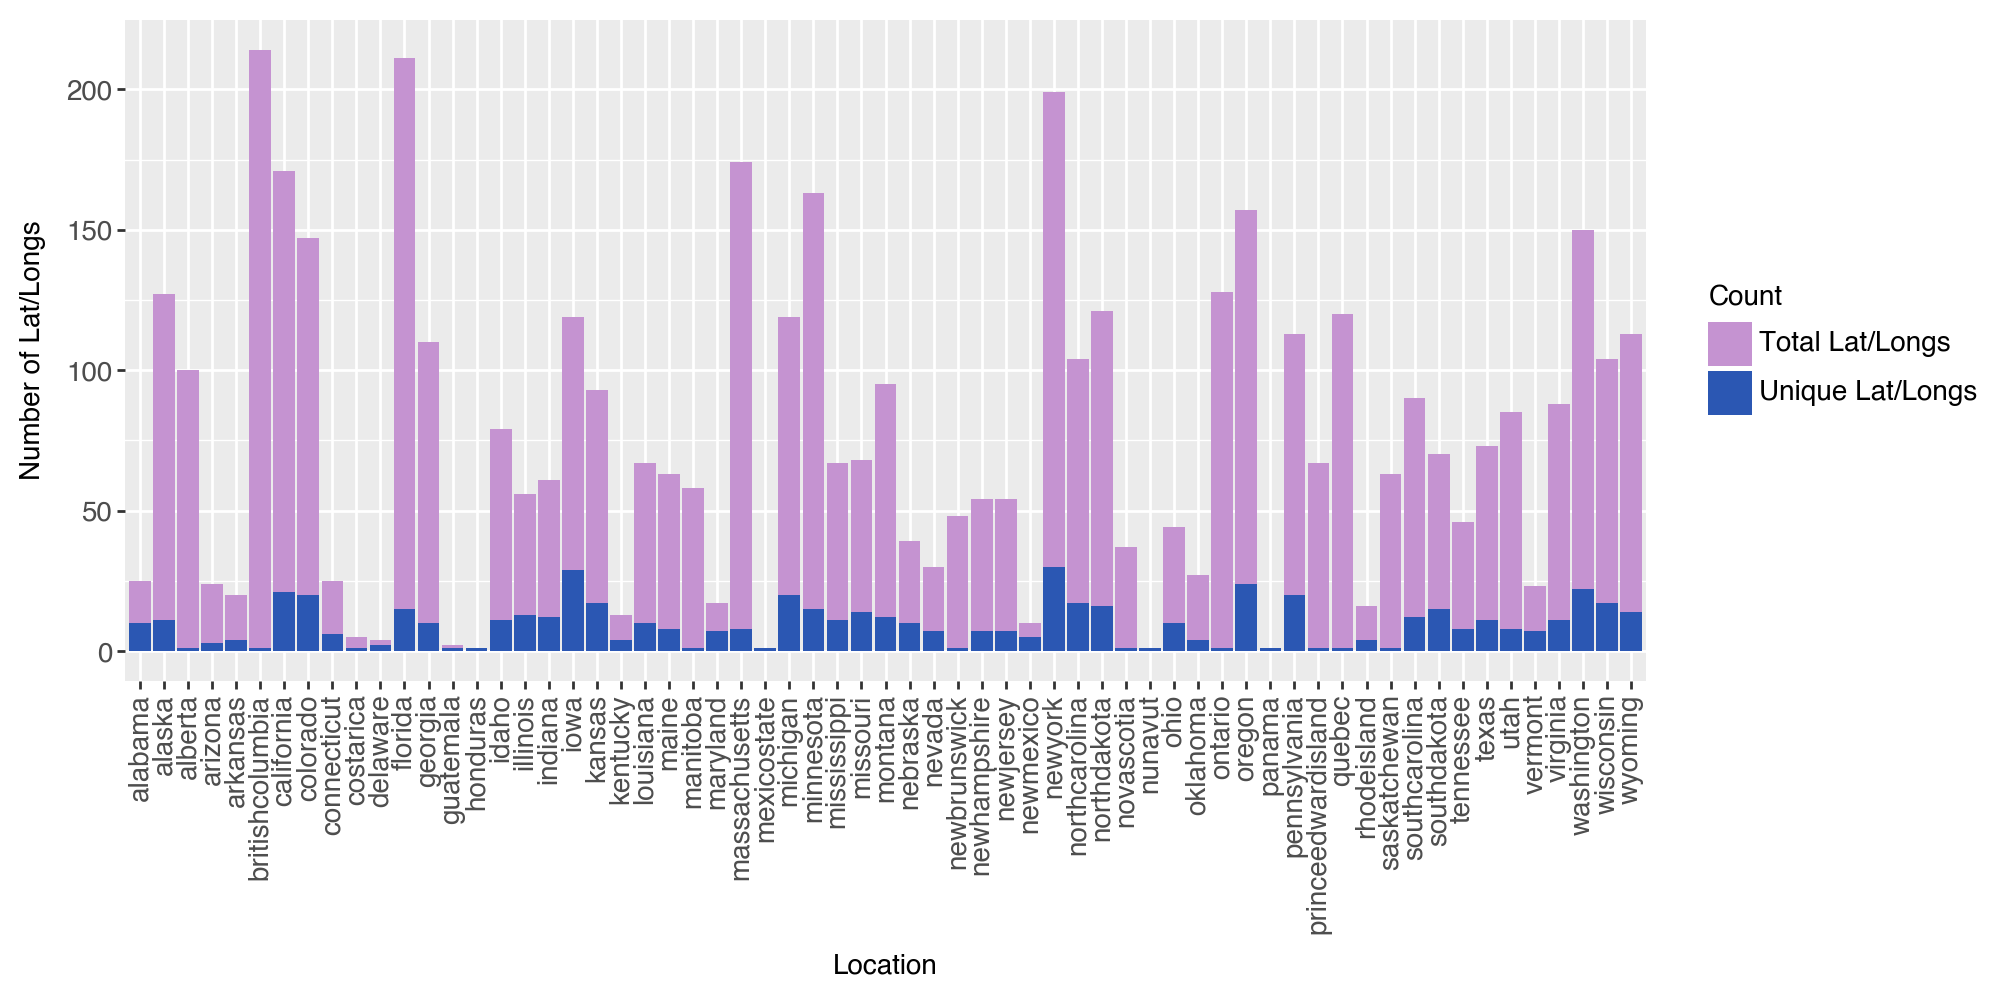

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:606: PlotnineWarning: Saving 20 x 10 in image.
/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:607: PlotnineWarning: Filename: /Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/metadata/exploratory_data_analysis/2022-2024_latlongs_by_location.png


In [123]:
# Add a dummy column to a copy of "timetree_sequences_filtered" to distinguish it

timetree_sequences_filtered_2 = timetree_sequences_filtered.copy()
timetree_sequences_filtered_2["Count"] = "total"

# Set color values
division_colors = {"total":"#C593D1", "unique": "#2B57B3"}

# Plot
uniquelatlong_per_division = (
    ggplot()
    + geom_col(data=timetree_sequences_filtered_2, mapping=aes(x='division', fill='Count'), stat='count', position='dodge')
    + geom_col(data=unique_per_division_df, mapping=aes(x='division', y='unique_latlong_count', fill='Count'), position='dodge')
    + scale_fill_manual(values={"total":"#C593D1", "unique": "#2B57B3"}, name="Count", labels={"total":"Total Lat/Longs", "unique": "Unique Lat/Longs"})
    + labs(x='Location', y='Number of Lat/Longs')
    + theme(axis_text_x=element_text(rotation=90), text=element_text(size=10))
    + theme(figure_size=(10, 5))
)

uniquelatlong_per_division.show()
uniquelatlong_per_division.save(filename = './metadata/exploratory_data_analysis/2022-2024_latlongs_by_location.png', height=10, width=20, units = 'in', dpi=750)

In [63]:
# Make a MAP of locations of tips across the tree

In [41]:
FILENAME = "./Nextstrain/2025-01-07_NAm_aves-wild_division2022/Nextstrain_results/ha_sequences_filtered-by-timetree.tsv"
timetree_sequences = pd.read_csv(FILENAME, sep = '\t')

# # Limit to just nonambig_date and lat_long_to_use
# columns = ["division"]
# timetree_sequences_filtered = timetree_sequences.loc[0:, columns]
# #print(timetree_sequences_filtered)

# Get value counts
timetree_sequences_valuecounts = timetree_sequences["division"].value_counts().reset_index()
timetree_sequences_valuecounts.columns = ['location', "count"]

In [42]:
# Load in the NaturalEarth shapefile as your map
states_path = "./metadata/ne_110m_admin_1_states_provinces/ne_110m_admin_1_states_provinces.shp"
states_gdf = gpd.read_file(states_path)

countries_path = "./metadata/ne_110m_admin_0_countries/ne_110m_admin_0_countries.shp"
countries_gdf = gpd.read_file(countries_path)

In [43]:
# Filter for U.S. states and desired countries

# Filter for US States
us_states = states_gdf[states_gdf['admin'] == 'United States of America']

# List of countries to include
country_list = [
    "Canada", "Mexico", 
    # "Panama", "Costa Rica", "Nicaragua",
    # "Honduras", "El Salvador", "Belize", "Guatemala"
]

selected_countries = countries_gdf[countries_gdf['ADMIN'].isin(country_list)]

In [44]:
# Reproject if needed (should be EPSG:4326 by default)
selected_countries = selected_countries.to_crs(us_states.crs)

# Combine both GeoDataFrames
combined_gdf = pd.concat([us_states, selected_countries], ignore_index=True)

In [45]:
# Create a DataFrame of lat/lon from the geometries
def geom_to_df(geom, region_name):
    if isinstance(geom, Polygon):
        coords = list(geom.exterior.coords)
        df = pd.DataFrame(coords, columns=['lon', 'lat'])
        df['region'] = region_name
        df['group'] = f"{region_name}_0"
        return df

    elif isinstance(geom, MultiPolygon):
        dfs = []
        for i, part in enumerate(geom.geoms):
            coords = list(part.exterior.coords)
            df = pd.DataFrame(coords, columns=['lon', 'lat'])
            df['region'] = region_name
            df['group'] = f"{region_name}_{i}"
            dfs.append(df)
            # Add a NaN row to break the path
            dfs.append(pd.DataFrame({'lon': [np.nan], 'lat': [np.nan], 'region': [region_name], 'group': [f"{region_name}_{i}"]}))
        return pd.concat(dfs, ignore_index=True)

    else:
        return pd.DataFrame(columns=['lon', 'lat', 'region', 'group'])

In [46]:
# Optional cleaning
combined_gdf = combined_gdf[combined_gdf.is_valid]
combined_gdf = combined_gdf[~combined_gdf.geometry.is_empty]

In [47]:
# Apply to all rows

map_df = pd.concat([
    geom_to_df(row.geometry, row['name']) for idx, row in combined_gdf.iterrows()
], ignore_index=True)

/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_13046/1863413258.py:10: FutureWarning: Using print(plot) to draw and show the plot figure is deprecated and will be removed in a future version. Use plot.show().


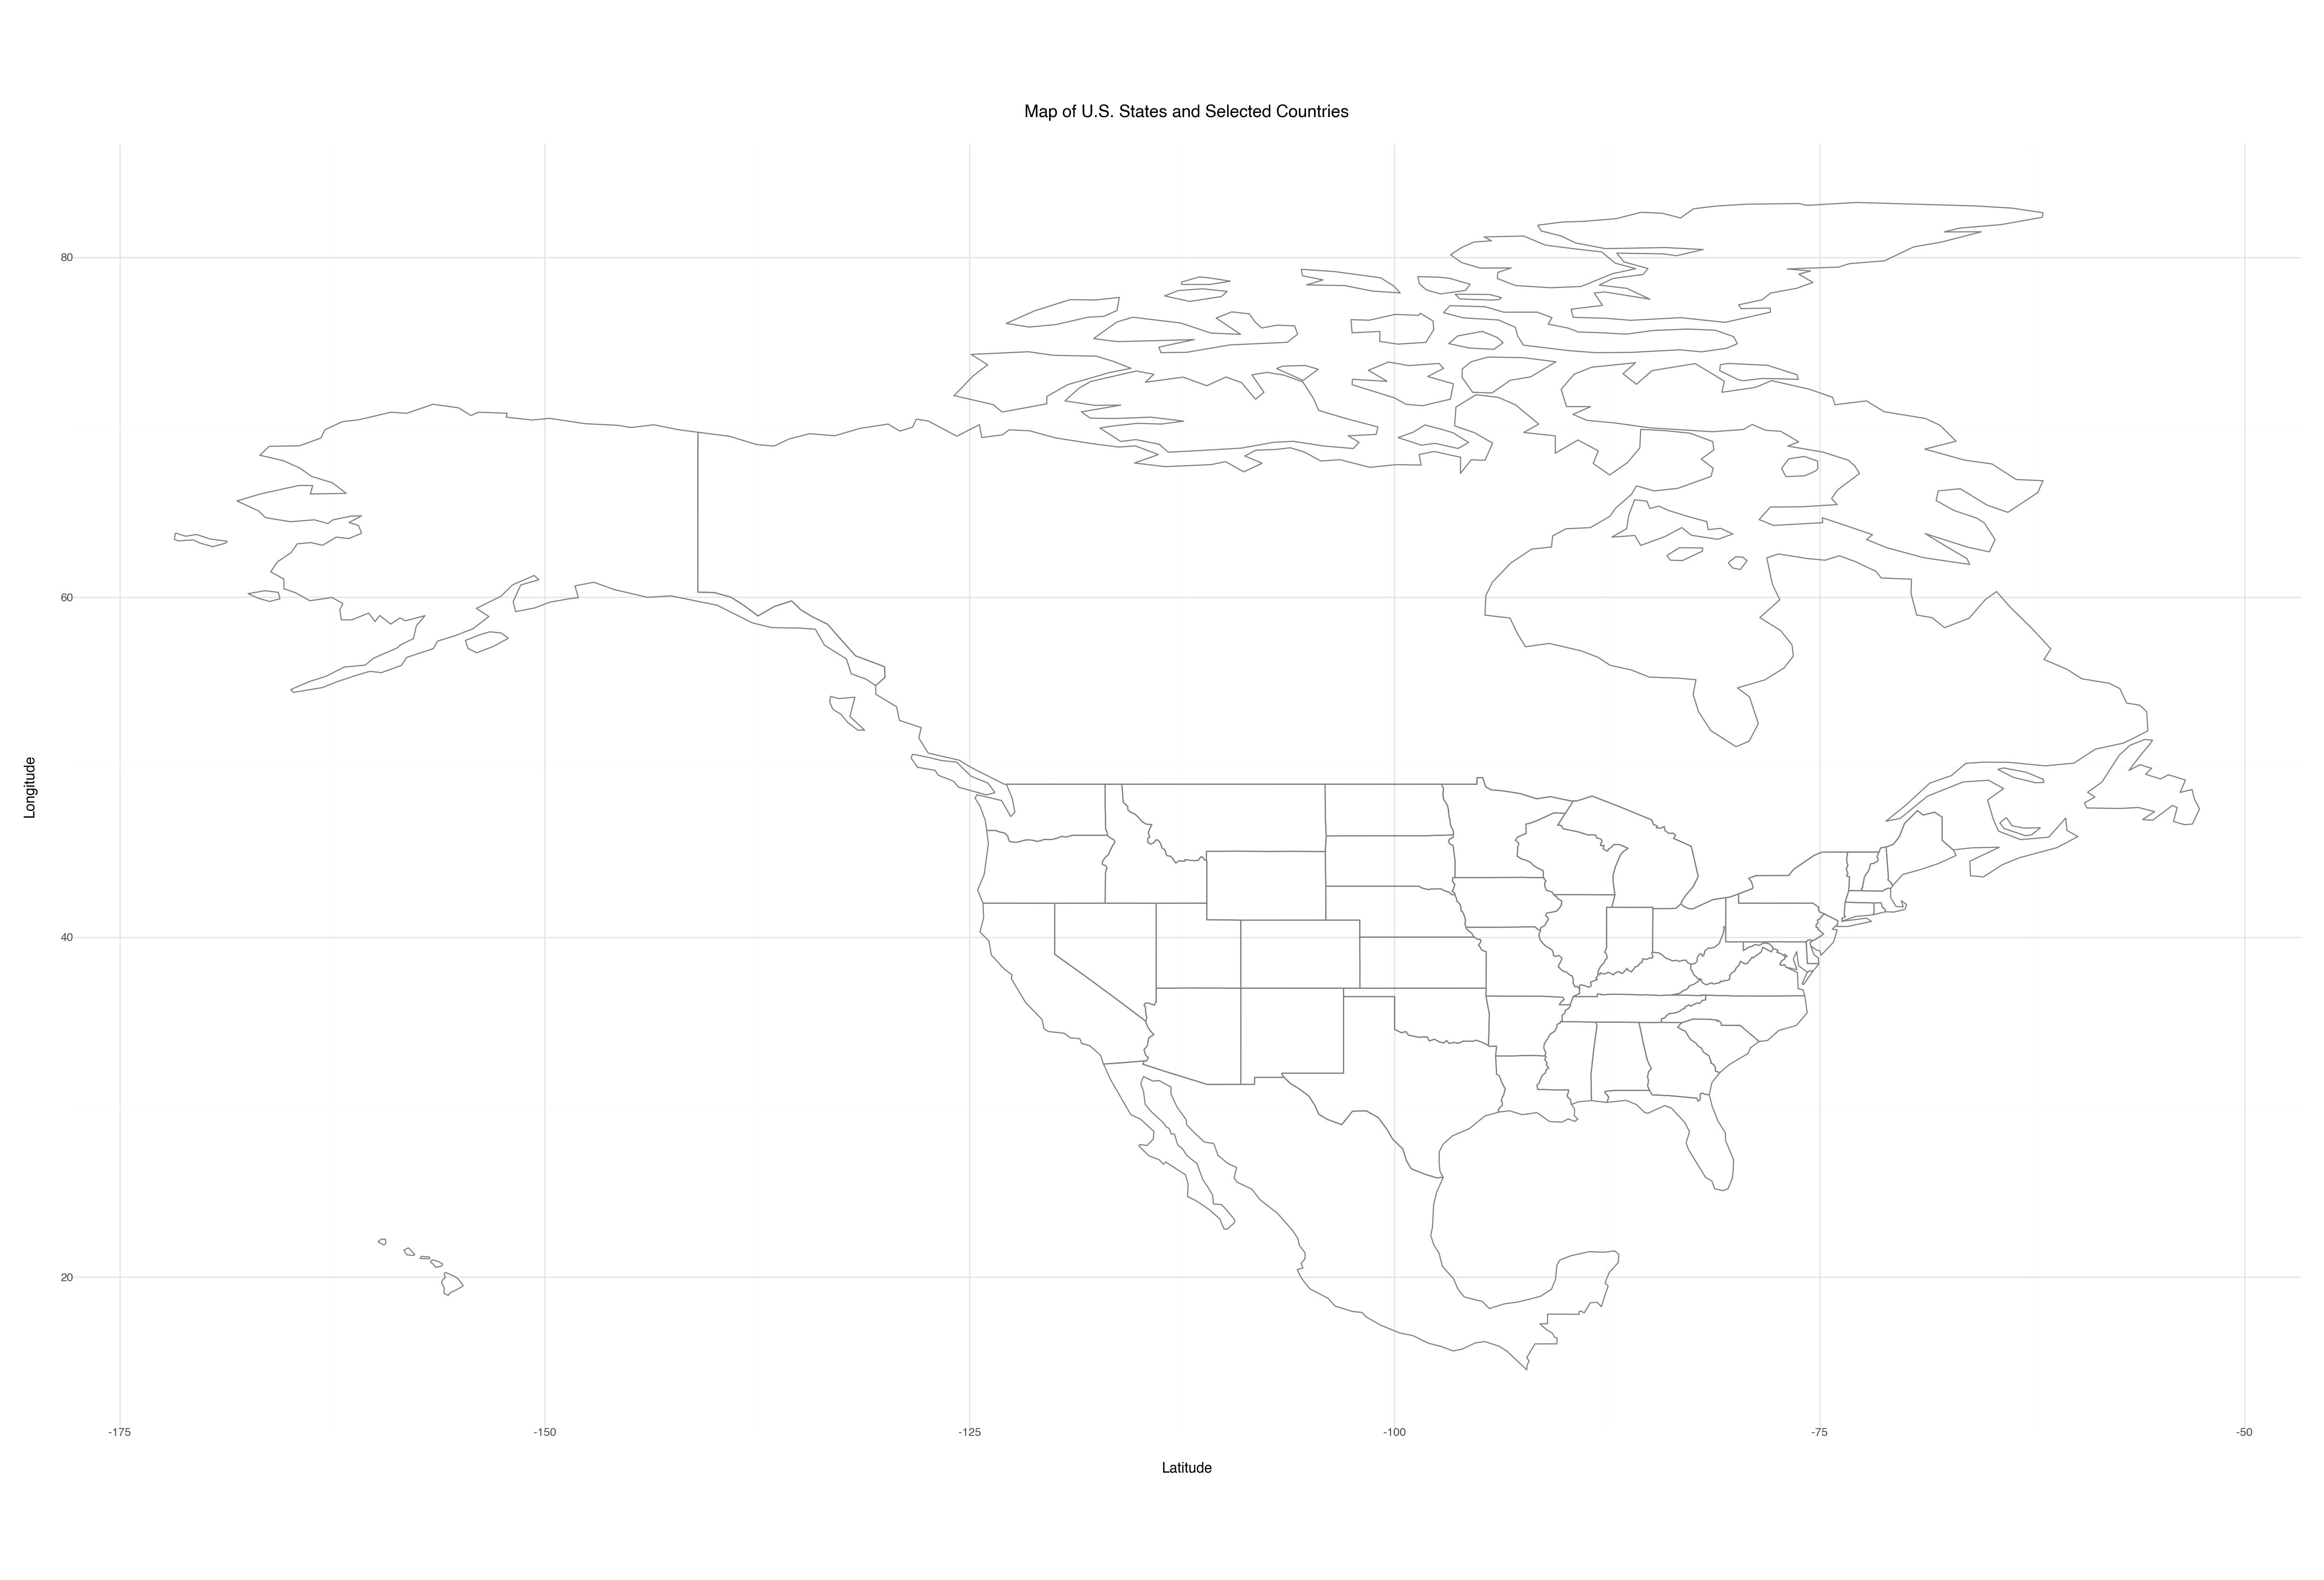

In [48]:
p = (
    ggplot(map_df) +
    geom_path(aes(x='lon', y='lat', group='group'), color='gray') +
    coord_fixed() +
    theme_minimal() +
    theme(figure_size=(25, 17)) +
    labs(title='Map of U.S. States and Selected Countries', x = "Latitude", y = "Longitude")
)

print(p)

In [49]:
# Import lat/longs for each division

state_latlongs = pd.read_csv("./metadata/helpful_lists/flywayregions_biggerlist.csv", sep = ',')

In [52]:
# Merge counts and coordinates
bubble_data = pd.merge(timetree_sequences_valuecounts, state_latlongs, on='location', how='left')

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 1 rows containing missing values.


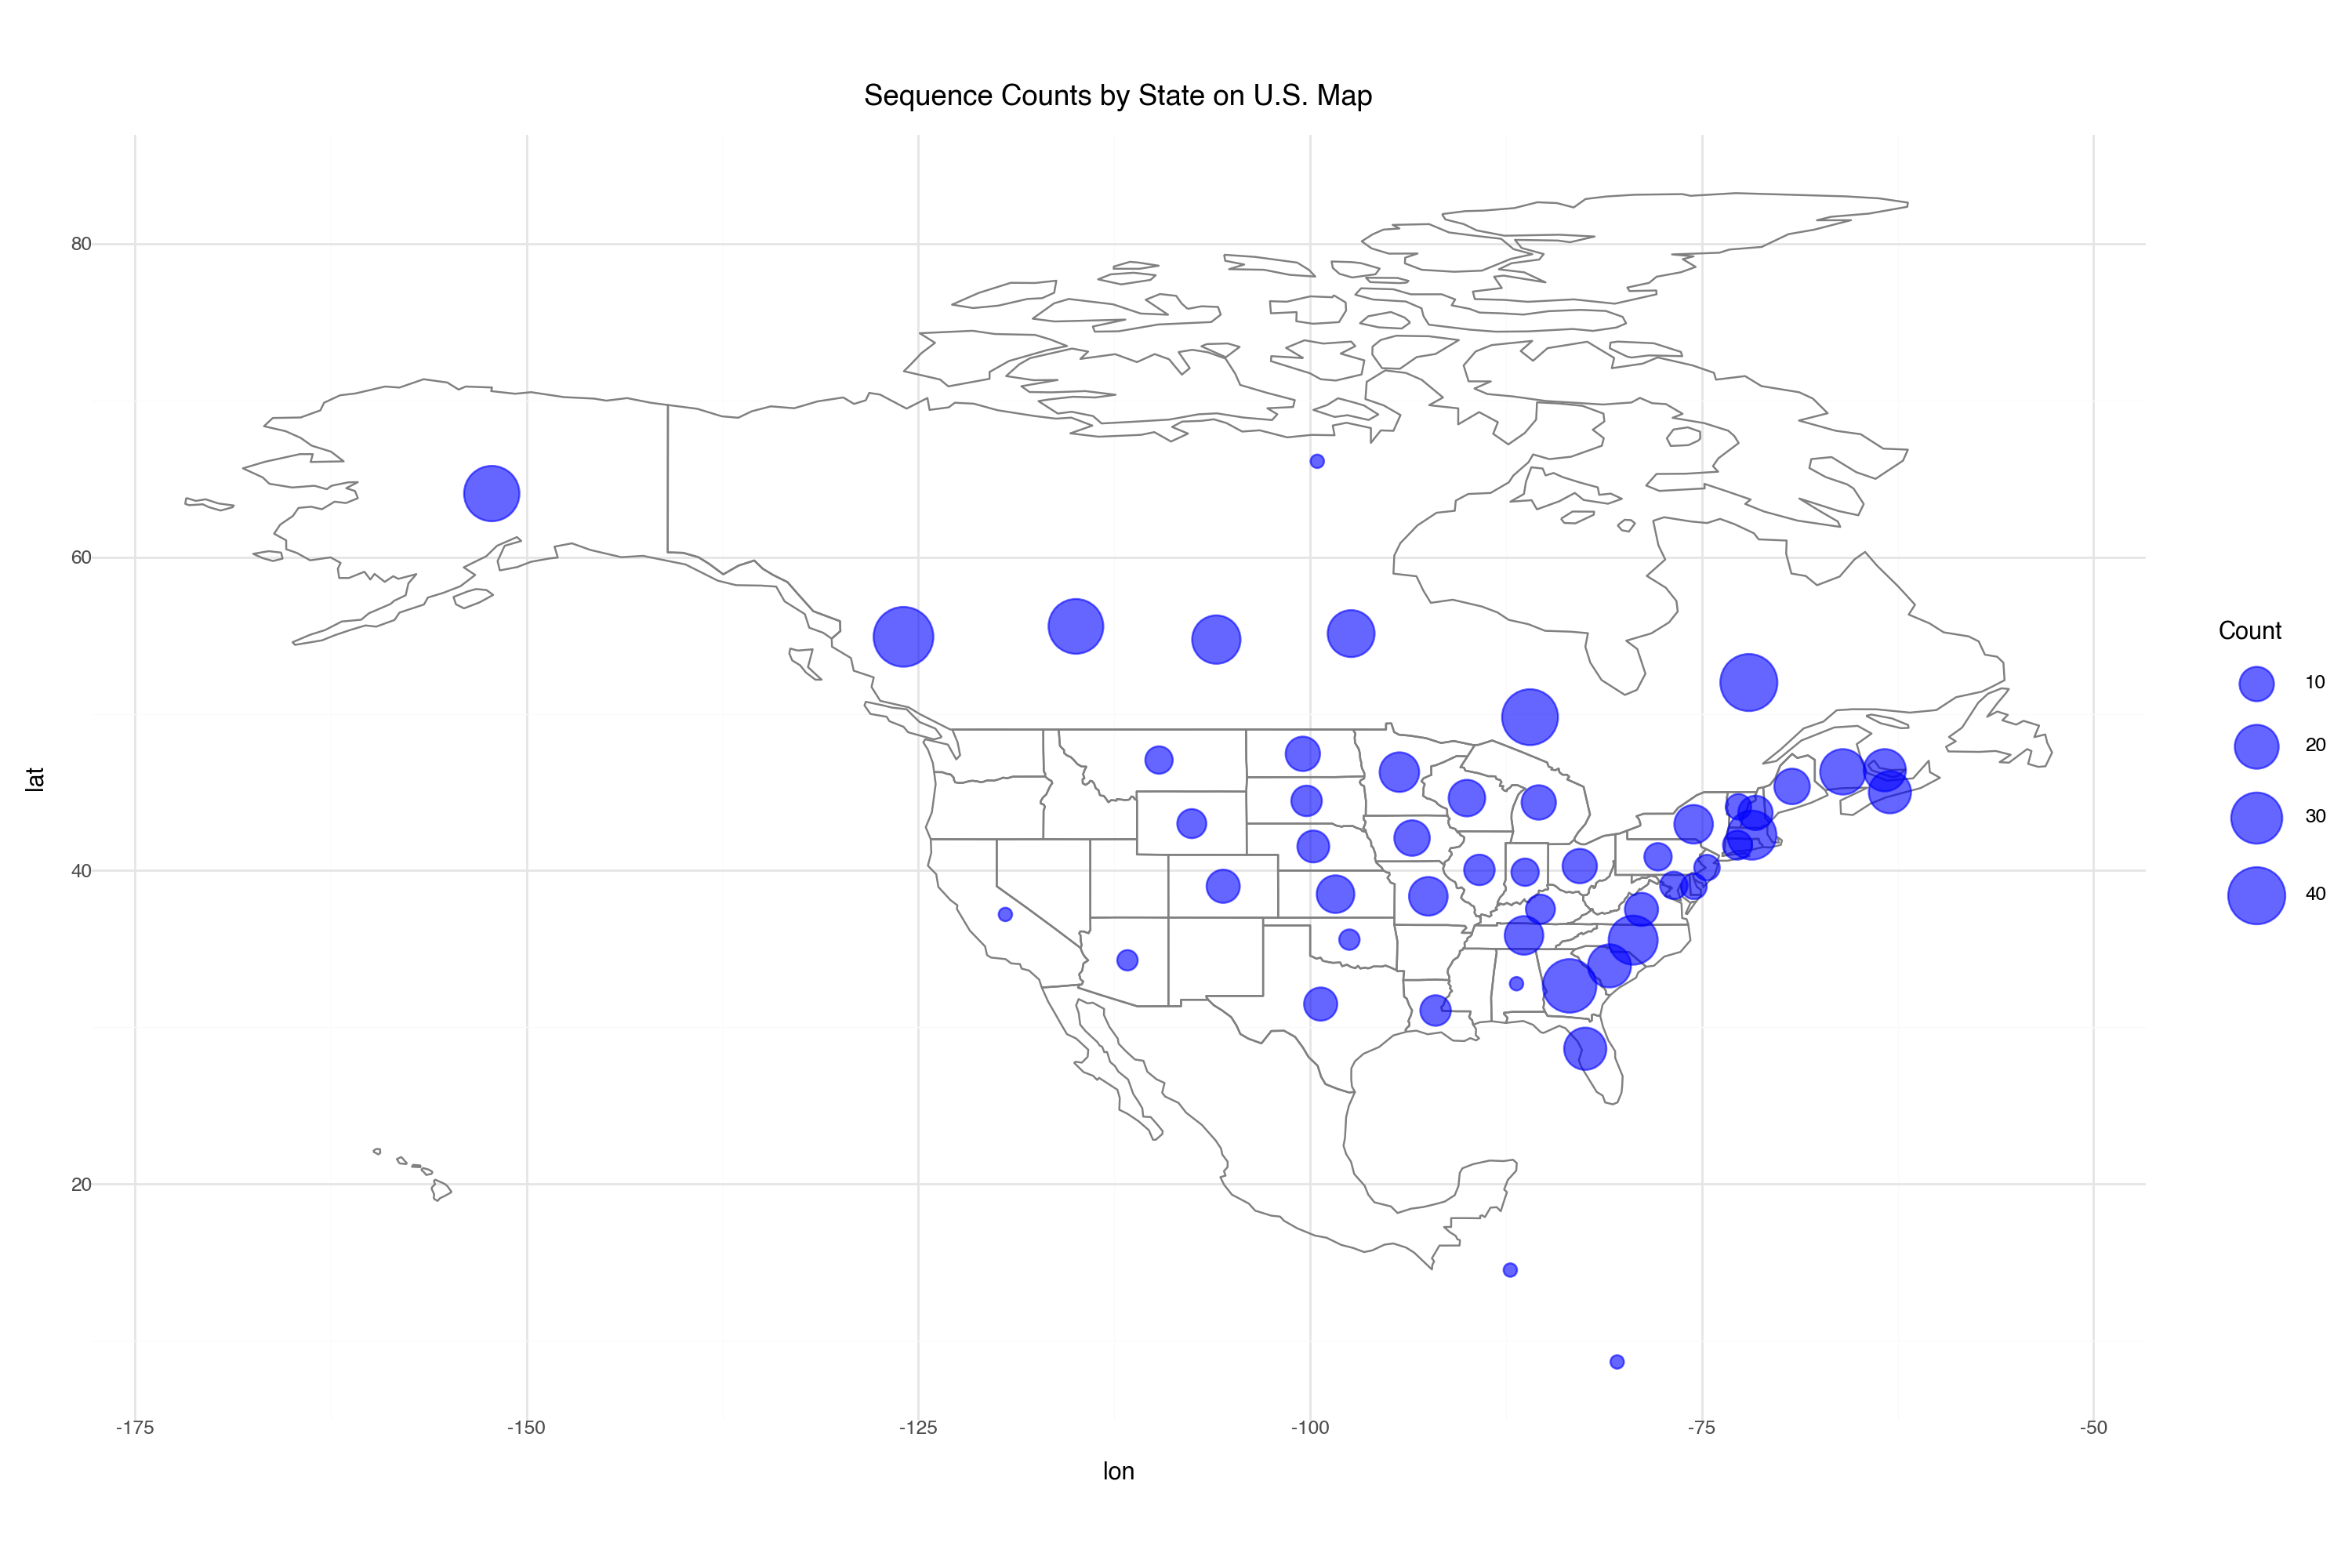

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:606: PlotnineWarning: Saving 20 x 10 in image.
/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:607: PlotnineWarning: Filename: /Users/claramal/Desktop/Moncla_Lab/H5_avian_ecology/Nextstrain/2025-01-07_NAm_aves-wild_division2022/Nextstrain_results/2022tree_locations.png
/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 1 rows containing missing values.


In [54]:
seqs_per_location_map = (
    ggplot(map_df) +
    geom_path(aes(x='lon', y='lat', group='group'), color='gray') +
    geom_point(data=bubble_data, mapping=aes(x='longitude', y='latitude', size='count'), color='blue', alpha=0.6) +
    scale_size_continuous(name="Count", range=(3, 15)) +
    coord_fixed() +
    theme_minimal() +
    theme(figure_size=(15, 10)) +
    labs(title='Sequence Counts by State on U.S. Map')
)

seqs_per_location_map.show()
seqs_per_location_map.save(filename = './Nextstrain/2025-01-07_NAm_aves-wild_division2022/Nextstrain_results/2022tree_locations.png', height=10, width=20, units = 'in', dpi=750)